# Cumplimiento del programa de producción
## Proyecto de visualización de datos – Avance 3: implementación técnica y reproducibilidad

**Pregunta analítica:** ¿Qué máquinas y tipos de operación concentran los retrasos y las fallas de las órdenes de trabajo, y cómo se relacionan estos incumplimientos con la disponibilidad de la máquina, el tiempo de proceso y el consumo de energía?

**Audiencia:** planeadores y supervisores de producción, jefes de mantenimiento y gerencia de operaciones.

Este notebook reproduce todo el proyecto, de principio a fin, en cinco secciones:

1. **Carga de datos**: lectura del archivo original sin modificarlo.
2. **Limpieza y transformación**: tipos de dato, variables derivadas y validaciones; genera el dataset limpio.
3. **EDA**: resumen numérico y regeneración de las 6 figuras del Avance 2.
4. **Visualizaciones finales**: (a) estática mejorada con matplotlib y (b) interactiva con Plotly.
5. **Exportación para BI**: archivo listo para Power BI o Tableau.

> Para ejecutarlo: instala las dependencias con `pip install -r requirements.txt`, abre este notebook desde la carpeta `notebooks/` y ejecuta *Run All*. Todas las rutas son relativas a la carpeta del proyecto.

In [1]:
# Configuración general: bibliotecas, rutas y paleta de colores del proyecto
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency
import plotly
import plotly.graph_objects as go

# Raíz del proyecto (funciona si el notebook se ejecuta desde notebooks/ o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "hybrid_manufacturing_raw.csv"
CLEAN = ROOT / "data" / "processed" / "hybrid_manufacturing_clean.csv"
BI = ROOT / "data" / "processed" / "ordenes_para_bi.csv"
FIG = ROOT / "outputs" / "figures"
HTML = ROOT / "outputs" / "interactive"
for p in [CLEAN.parent, FIG, HTML]:
    p.mkdir(parents=True, exist_ok=True)

# Paleta única del proyecto: el mismo color significa lo mismo en todas las gráficas (teoría 3.4.11)
COLOR = {"Completada": "#3A6EA5", "Retrasada": "#E09A2B", "Fallida": "#B8322A"}
FUENTE = "Fuente: elaboración propia con datos de ziya07 (s.f.), Manufacturing Production Data, Kaggle."

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| plotly", plotly.__version__)
print("Raíz del proyecto:", ROOT)

pandas 3.0.5 | matplotlib 3.11.2 | plotly 7.1.0
Raíz del proyecto: /home/claude/proyecto_visualizacion_manufactura


## 1. Carga de datos

**Fuente:** ziya07 (s.f.). *Manufacturing Production Data* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/ziya07/manufacturing-production-data

| Campo | Valor |
|---|---|
| Archivo original | `hybrid_manufacturing_categorical.csv` (guardado como `data/raw/hybrid_manufacturing_raw.csv`) |
| Fecha de descarga | octubre de 2026 (versión disponible en Kaggle en esa fecha) |
| Periodo que cubre | 18 al 25 de marzo de 2023 |
| Registros | 1,000 órdenes de trabajo, 13 columnas |
| Unidades | tiempos en minutos; disponibilidad en %; energía y material sin unidad declarada (se suponen kWh y kg) |
| Limitaciones conocidas | probablemente datos simulados; sin información de operadores, turnos ni causas de falla |

El archivo de `data/raw/` **nunca se modifica**: todas las transformaciones generan un archivo nuevo en `data/processed/` (teoría 3.4.5).

In [2]:
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(1000, 13)


,Job_ID,Machine_ID,Operation_Type,Material_Used,Processing_Time,Energy_Consumption,Machine_Availability,Scheduled_Start,Scheduled_End,Actual_Start,Actual_End,Job_Status,Optimization_Category
0,J001,M01,Grinding,3.17,76,11.42,96,2023-03-18 08:00:00,2023-03-18 09:16:00,2023-03-18 08:05:00,2023-03-18 09:21:00,Completed,Moderate Efficiency
1,J002,M01,Grinding,3.35,79,6.61,84,2023-03-18 08:10:00,2023-03-18 09:29:00,2023-03-18 08:20:00,2023-03-18 09:39:00,Delayed,Low Efficiency
2,J003,M04,Additive,2.29,56,11.11,92,2023-03-18 08:20:00,2023-03-18 09:16:00,NaN,NaN,Failed,Low Efficiency
3,J004,M04,Grinding,1.76,106,12.50,95,2023-03-18 08:30:00,2023-03-18 10:16:00,2023-03-18 08:35:00,2023-03-18 10:21:00,Completed,Moderate Efficiency
4,J005,M01,Lathe,1.90,46,8.13,88,2023-03-18 08:40:00,2023-03-18 09:26:00,2023-03-18 08:42:00,2023-03-18 09:28:00,Completed,High Efficiency


In [3]:
# Revisión inicial: tipos de dato, valores faltantes y duplicados
print(raw.dtypes, "\n")
print("Valores faltantes por columna:\n", raw.isna().sum()[raw.isna().sum() > 0], "\n")
print("Filas duplicadas:", raw.duplicated().sum(), "| Job_ID duplicados:", raw["Job_ID"].duplicated().sum())

Job_ID                       str
Machine_ID                   str
Operation_Type               str
Material_Used            float64
Processing_Time            int64
Energy_Consumption       float64
Machine_Availability       int64
Scheduled_Start              str
Scheduled_End                str
Actual_Start                 str
Actual_End                   str
Job_Status                   str
Optimization_Category        str
dtype: object 

Valores faltantes por columna:
 Actual_Start    129
Actual_End      129
dtype: int64 

Filas duplicadas: 0 | Job_ID duplicados: 0


## 2. Limpieza y transformación

Hallazgos de la revisión y decisiones tomadas. **No se elimina ninguna fila.**

| # | Transformación | Motivo |
|---|---|---|
| T1 | Convertir las 4 columnas de fecha y hora a tipo `datetime` | Permite calcular diferencias de tiempo y agrupar por día |
| T2 | Mantener vacíos `Actual_Start` y `Actual_End` en las 129 órdenes fallidas | No son errores: una orden fallida nunca inició. Se verifica que los vacíos coincidan exactamente con `Job_Status = Failed` |
| T3 | Crear `Retraso_inicio_min` = `Actual_Start` − `Scheduled_Start` (minutos) | Mide el desfase contra el programa |
| T4 | Crear `Incumplimiento` = 1 si la orden está retrasada o fallida | Indicador principal de la pregunta analítica |
| T5 | Crear `Fecha` (día) y `Hora` a partir de `Scheduled_Start` | Análisis temporal |
| T6 | Traducir estado y operación al español (`Estado`, `Operacion`) | Etiquetas consistentes con el reporte; se conservan las columnas originales |
| T7 | Crear `Rango_disponibilidad` (80–84, 85–89, 90–94, 95–99 %) | Permite comparar grupos en BI |

In [4]:
df = raw.copy()

# T1. Tipos de fecha
for c in ["Scheduled_Start", "Scheduled_End", "Actual_Start", "Actual_End"]:
    df[c] = pd.to_datetime(df[c])

# T2. Validación: los vacíos corresponden exactamente a las órdenes fallidas
assert (df["Actual_Start"].isna() == (df["Job_Status"] == "Failed")).all(), "Vacíos inesperados"

# T3. Retraso en el inicio (minutos); queda vacío en las órdenes fallidas
df["Retraso_inicio_min"] = (df["Actual_Start"] - df["Scheduled_Start"]).dt.total_seconds() / 60

# T4. Indicador de incumplimiento
df["Incumplimiento"] = (df["Job_Status"] != "Completed").astype(int)

# T5. Fecha y hora programadas
df["Fecha"] = df["Scheduled_Start"].dt.normalize()
df["Hora"] = df["Scheduled_Start"].dt.hour

# T6. Etiquetas en español
df["Estado"] = df["Job_Status"].map({"Completed": "Completada", "Delayed": "Retrasada", "Failed": "Fallida"})
df["Operacion"] = df["Operation_Type"].map({"Additive": "Aditiva", "Drilling": "Taladrado",
                                            "Grinding": "Rectificado", "Lathe": "Torno", "Milling": "Fresado"})

# T7. Rangos de disponibilidad
df["Rango_disponibilidad"] = pd.cut(df["Machine_Availability"], [79, 84, 89, 94, 99],
                                    labels=["80–84 %", "85–89 %", "90–94 %", "95–99 %"]).astype(str)

assert df["Estado"].notna().all() and df["Operacion"].notna().all()
df.to_csv(CLEAN, index=False)
print("Dataset limpio guardado en", CLEAN.relative_to(ROOT), df.shape)

Dataset limpio guardado en data/processed/hybrid_manufacturing_clean.csv (1000, 20)


## 3. Exploración de datos (EDA)

Resumen numérico que respalda los hallazgos del Avance 2. Las seis figuras del Avance 2 se regeneran con el script `src/eda_avance2.py`, a partir del mismo archivo original.

In [5]:
print(f"Órdenes: {len(df)} | Incumplimiento total: {df['Incumplimiento'].mean():.1%}")
print(df["Estado"].value_counts(normalize=True).round(3), "\n")

def wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson al 95 % para una proporción
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return p, c - h, c + h

print("Incumplimiento por máquina (IC 95 % de Wilson):")
for m, g in df.groupby("Machine_ID"):
    p, lo, hi = wilson(g["Incumplimiento"].sum(), len(g))
    print(f"  {m} (n={len(g)}): {p:.1%} [{lo:.1%} – {hi:.1%}]")

for col in ["Machine_ID", "Operation_Type"]:
    chi2, pval = chi2_contingency(pd.crosstab(df[col], df["Job_Status"]))[:2]
    print(f"Ji cuadrada {col}: chi2 = {chi2:.1f}, p = {pval:.2f}")

Órdenes: 1000 | Incumplimiento total: 32.7%
Estado
Completada    0.673
Retrasada     0.198
Fallida       0.129
Name: proportion, dtype: float64 

Incumplimiento por máquina (IC 95 % de Wilson):
  M01 (n=212): 28.3% [22.7% – 34.7%]
  M02 (n=210): 30.5% [24.6% – 37.0%]
  M03 (n=186): 33.9% [27.5% – 40.9%]
  M04 (n=199): 35.7% [29.4% – 42.5%]
  M05 (n=193): 35.8% [29.3% – 42.7%]
Ji cuadrada Machine_ID: chi2 = 12.1, p = 0.15
Ji cuadrada Operation_Type: chi2 = 3.7, p = 0.89


In [6]:
# Porcentaje diario por estado (base de la visualización estática final)
diario = (pd.crosstab(df["Fecha"], df["Estado"], normalize="index")
            .join(df.groupby("Fecha").size().rename("n")))
diario

,Completada,Fallida,Retrasada,n
Fecha,,,,
2023-03-18,0.656250,0.114583,0.229167,96
2023-03-19,0.694444,0.152778,0.152778,144
2023-03-20,0.743056,0.111111,0.145833,144
2023-03-21,0.666667,0.104167,0.229167,144
2023-03-22,0.631944,0.131944,0.236111,144
2023-03-23,0.604167,0.152778,0.243056,144
2023-03-24,0.715278,0.125000,0.159722,144
2023-03-25,0.650000,0.150000,0.200000,40


## 4. Visualizaciones finales

### 4a. Visualización estática (matplotlib): evolución diaria de los retrasos

Versión **explicativa** de la Figura 4 del Avance 2. Ahora tiene un título que enuncia el hallazgo, una banda que señala el pico de mitad de semana, una línea de referencia con el promedio de la semana, etiquetas directas y una nota con el periodo, la definición de las métricas y la fuente (teoría 3.4.10).

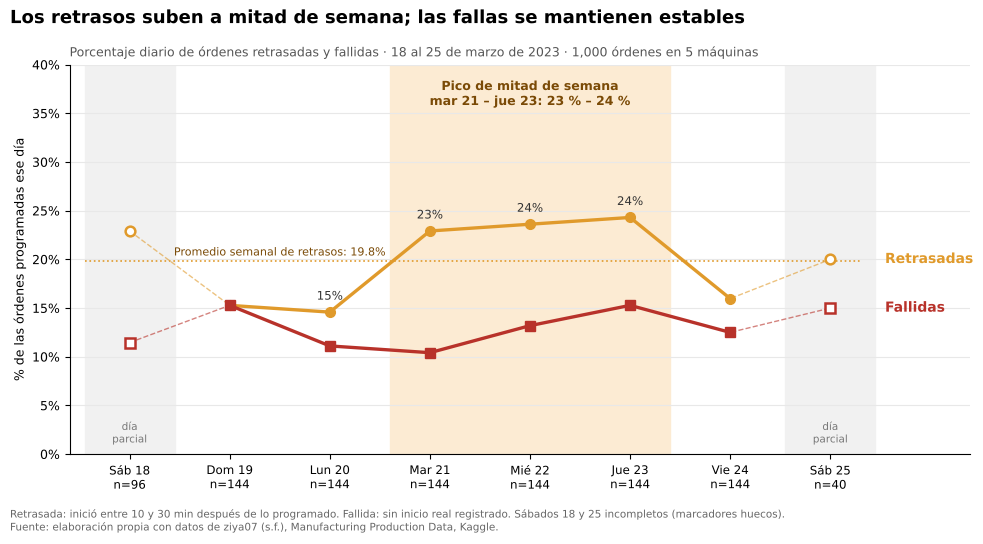

In [7]:
d = diario.copy()
x = np.arange(len(d))
dias = {"Mon": "Lun", "Tue": "Mar", "Wed": "Mié", "Thu": "Jue", "Fri": "Vie", "Sat": "Sáb", "Sun": "Dom"}
etiquetas = [f"{dias[f.strftime('%a')]} {f.day}\nn={n}" for f, n in zip(d.index, d["n"])]
prom_retraso = (df["Estado"] == "Retrasada").mean()
completos = d["n"] == d["n"].max()  # días con jornada completa (144 órdenes)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axvspan(2.6, 5.4, color="#FCEBD3", zorder=0)
ax.text(4, 0.385, "Pico de mitad de semana\nmar 21 – jue 23: 23 % – 24 %", ha="center", va="top",
        fontsize=9, color="#7A4A06", fontweight="bold")
for i in [0, len(d) - 1]:
    ax.axvspan(i - 0.45, i + 0.45, color="#F1F1F1", zorder=0)
    ax.text(i, 0.012, "día\nparcial", ha="center", fontsize=7.5, color="#777")

ax.hlines(prom_retraso, -0.45, len(d) - 0.7, color="#E09A2B", lw=1.2, ls=":", zorder=1)
ax.text(1.5, prom_retraso + 0.006, f"Promedio semanal de retrasos: {prom_retraso:.1%}",
        ha="center", fontsize=8, color="#7A4A06")

for est, mk in [("Retrasada", "o"), ("Fallida", "s")]:
    ax.plot(x[completos], d[est][completos], color=COLOR[est], lw=2.4, marker=mk, ms=7, zorder=3)
    ax.plot(x, d[est], color=COLOR[est], lw=1, ls="--", alpha=0.6, zorder=2)   # días parciales en punteado
    ax.plot(x[~completos], d[est][~completos], color=COLOR[est], marker=mk, ms=7, mfc="white", mew=1.8, ls="none", zorder=3)
    ax.text(len(d) - 0.55, d[est].iloc[-1], f"  {est}s", color=COLOR[est], va="center", fontsize=10, fontweight="bold")
for i in [2, 3, 4, 5]:
    ax.annotate(f"{d['Retrasada'].iloc[i]:.0%}", (x[i], d["Retrasada"].iloc[i]), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=8.5, color="#333")

ax.set_xticks(x); ax.set_xticklabels(etiquetas, fontsize=8.5)
ax.set_xlim(-0.6, len(d) + 0.4); ax.set_ylim(0, 0.40)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("% de las órdenes programadas ese día")
ax.grid(axis="y", color="#E8E8E8", lw=0.8); ax.set_axisbelow(True)
fig.suptitle("Los retrasos suben a mitad de semana; las fallas se mantienen estables",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
ax.set_title("Porcentaje diario de órdenes retrasadas y fallidas · 18 al 25 de marzo de 2023 · 1,000 órdenes en 5 máquinas",
             loc="left", fontsize=9, color="#555")
fig.text(0.01, 0.015, "Retrasada: inició entre 10 y 30 min después de lo programado. Fallida: sin inicio real registrado. "
         "Sábados 18 y 25 incompletos (marcadores huecos).\n" + FUENTE, fontsize=7.5, color="#666")
fig.tight_layout(rect=[0, 0.06, 1, 0.995])
fig.savefig(FIG / "fig_estatica_retrasos_por_dia.png", dpi=200)
plt.show()

### 4b. Visualización interactiva (Plotly): estado de las órdenes por máquina y operación

Integra en una sola vista las Figuras 2 y 3 del Avance 2. El **estado por defecto** ya responde la pregunta principal: todas las operaciones juntas, con las máquinas ordenadas de mejor a peor (teoría 3.2.6). La interacción agrega detalle bajo demanda (teoría 3.2.2):

* **Filtro** (menú desplegable): elige un tipo de operación y las barras se recalculan.
* **Hover**: muestra el porcentaje, el número de órdenes, el total de la máquina, el retraso promedio y el intervalo de confianza del incumplimiento.
* **Leyenda**: un clic oculta o muestra un estado, por ejemplo para ver solo las fallas.

In [8]:
ESTADOS = ["Completada", "Retrasada", "Fallida"]
OPS = ["Todas las operaciones"] + sorted(df["Operacion"].unique())
orden_maquinas = (df.groupby("Machine_ID")["Incumplimiento"].mean().sort_values(ascending=False).index.tolist())

def resumen(sub):
    # Tabla máquina × estado con conteos, porcentajes y datos para el hover
    t = pd.crosstab(sub["Machine_ID"], sub["Estado"]).reindex(index=orden_maquinas, columns=ESTADOS, fill_value=0)
    n = t.sum(axis=1)
    ret = sub.groupby("Machine_ID")["Retraso_inicio_min"].mean().reindex(orden_maquinas)
    ic = [wilson(k, m) for k, m in zip(t["Retrasada"] + t["Fallida"], n)]
    return t, n, ret, ic

fig = go.Figure()
botones = []
for j, op in enumerate(OPS):
    sub = df if j == 0 else df[df["Operacion"] == op]
    t, n, ret, ic = resumen(sub)
    for est in ESTADOS:
        custom = np.column_stack([t[est], n, ret.round(1), [f"{p:.0%} [{lo:.0%}–{hi:.0%}]" for p, lo, hi in ic]])
        fig.add_bar(
            y=orden_maquinas, x=t[est] / n, orientation="h", name=est, marker_color=COLOR[est],
            marker_line=dict(color="white", width=1.5), visible=(j == 0), legendgroup=est, showlegend=(j == 0),
            text=[f"{v:.0%}" for v in t[est] / n], textposition="inside", insidetextanchor="middle",
            textfont=dict(color="white" if est != "Retrasada" else "#222"),
            customdata=custom,
            hovertemplate=("<b>%{y} · " + est + "</b><br>%{x:.1%} de las órdenes (%{customdata[0]} de %{customdata[1]})"
                           "<br>Retraso promedio de las órdenes ejecutadas de la máquina: %{customdata[2]} min"
                           "<br>Incumplimiento total [IC 95 %]: %{customdata[3]}<extra>" + op + "</extra>"))
    vis = [False] * (len(OPS) * 3); vis[j * 3:(j + 1) * 3] = [True] * 3
    botones.append(dict(label=op, method="update",
                        args=[{"visible": vis},
                              {"title.text": f"<b>Estado de las órdenes por máquina</b> · {op} (n = {len(sub):,})"}]))

fig.update_layout(
    barmode="stack", template="simple_white", height=480, margin=dict(l=70, r=30, t=110, b=130),
    title=dict(text=f"<b>Estado de las órdenes por máquina</b> · Todas las operaciones (n = {len(df):,})", x=0.01, font_size=18),
    xaxis=dict(tickformat=".0%", range=[0, 1], title="Porcentaje de órdenes de la máquina"),
    yaxis=dict(title="", categoryorder="array", categoryarray=orden_maquinas[::-1]),
    legend=dict(orientation="h", x=0.99, xanchor="right", y=1.12, title_text="", traceorder="normal"),
    updatemenus=[dict(buttons=botones, direction="down", x=0.01, xanchor="left", y=1.14, yanchor="top",
                      showactive=True, bgcolor="white", bordercolor="#BBB")],
    hoverlabel=dict(bgcolor="white", font_size=12),
    annotations=[dict(text="Pasa el cursor sobre una barra para ver el detalle · Clic en la leyenda para ocultar un estado · "
                           "Máquinas ordenadas de mayor a menor incumplimiento.<br>" + FUENTE,
                      x=0, y=-0.32, xref="paper", yref="paper", showarrow=False, align="left",
                      font=dict(size=10, color="#666"))])
fig.write_html(HTML / "interactiva_estado_por_maquina.html", include_plotlyjs=True)
fig.show()

## 5. Exportación para la herramienta de BI

Se exporta un archivo con nombres de columna en español y solo las variables que usa el tablero de Power BI o Tableau. La lógica de las métricas se documenta en `bi/guia_power_bi.md`.

In [9]:
cols = {"Job_ID": "Orden", "Machine_ID": "Maquina", "Operacion": "Operacion", "Estado": "Estado",
        "Incumplimiento": "Incumplimiento", "Fecha": "Fecha", "Hora": "Hora",
        "Processing_Time": "Tiempo_proceso_min", "Retraso_inicio_min": "Retraso_inicio_min",
        "Machine_Availability": "Disponibilidad_pct", "Rango_disponibilidad": "Rango_disponibilidad",
        "Energy_Consumption": "Energia", "Optimization_Category": "Categoria_eficiencia"}
bi = df[list(cols)].rename(columns=cols)
bi["Fecha"] = bi["Fecha"].dt.strftime("%Y-%m-%d")
bi.to_csv(BI, index=False, encoding="utf-8-sig")
print("Exportado:", BI.relative_to(ROOT), bi.shape)
bi.head()

Exportado: data/processed/ordenes_para_bi.csv (1000, 13)


,Orden,Maquina,Operacion,Estado,Incumplimiento,Fecha,Hora,Tiempo_proceso_min,Retraso_inicio_min,Disponibilidad_pct,Rango_disponibilidad,Energia,Categoria_eficiencia
0,J001,M01,Rectificado,Completada,0,2023-03-18,8,76,5.0,96,95–99 %,11.42,Moderate Efficiency
1,J002,M01,Rectificado,Retrasada,1,2023-03-18,8,79,10.0,84,80–84 %,6.61,Low Efficiency
2,J003,M04,Aditiva,Fallida,1,2023-03-18,8,56,NaN,92,90–94 %,11.11,Low Efficiency
3,J004,M04,Rectificado,Completada,0,2023-03-18,8,106,5.0,95,95–99 %,12.50,Moderate Efficiency
4,J005,M01,Torno,Completada,0,2023-03-18,8,46,2.0,88,85–89 %,8.13,High Efficiency


## Validación final (teoría 3.4.12)

Se comprueba que los archivos y las cifras clave coincidan con lo reportado en el documento.

In [10]:
assert len(df) == 1000 and df["Job_ID"].is_unique
assert round(df["Incumplimiento"].mean(), 3) == 0.327
assert (df.loc[df["Estado"] == "Completada", "Retraso_inicio_min"].between(-5, 5)).all()
assert (df.loc[df["Estado"] == "Retrasada", "Retraso_inicio_min"].between(10, 30)).all()
for f in [CLEAN, BI, FIG / "fig_estatica_retrasos_por_dia.png", HTML / "interactiva_estado_por_maquina.html"]:
    assert f.exists(), f
print("Validación correcta: todos los archivos se generaron y las cifras coinciden.")

Validación correcta: todos los archivos se generaron y las cifras coinciden.
